# EDA reproducible del corpus y consultas FiQA

**Issue #4 · Jorge Torres · Recuperación de Información, EPN · Prof. Iván Carrera**

Este análisis describe el corpus completo y las consultas **test** de FiQA (BEIR).
Su objetivo es sustentar la descripción del corpus del informe (#17), comprobar la
integridad de datos y caracterizar las representaciones léxicas acordadas. No ejecuta
recuperadores ni mide su efectividad. Los datos se descargan con `ris.data` (#2) y las
variantes clásicas se obtienen exclusivamente con `ris.preprocessing.preprocess` (#3).

Fuentes de requisitos: [especificación](../docs/ESPECIFICACION.md),
[criterios de #4](https://github.com/Vladimirjon/Retrieval_Information_System/issues/4),
[plan y contratos](../docs/PLAN.md) y [dataset verificado](../docs/DATASET.md).
Los resultados siguientes se calculan al ejecutar; las cifras previas se usan solo
como comprobaciones de integración, nunca para rellenar resultados ausentes.

## 1. Reproducción y entorno

Desde la raíz, con Python 3.12 y las dependencias de `requirements.txt` instaladas:

```powershell
python -m pip install --no-deps -e .
python -m ipykernel install --prefix .venv --name ris-eda --display-name "Python 3.12 (RIS EDA)"
python -m jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=1800 --ExecutePreprocessor.kernel_name=ris-eda notebooks/04_eda_fiqa.ipynb
```

También puede abrirse con JupyterLab y ejecutarse de principio a fin usando el kernel
del entorno. Se detecta la raíz tanto desde ella como desde `notebooks/`. La primera
ejecución necesita red para FiQA, `punkt_tab` y stopwords; las siguientes reutilizan
`data/`. Sin aleatoriedad ni muestreo. Se escriben únicamente los agregados pequeños
`reports/eda_summary.json` y `docs/informe/04_descripcion_corpus.md`. No se exportan
textos, tokens completos, embeddings, índices ni PDF docentes.

In [1]:
import os
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").is_file():
    raise RuntimeError("Ejecutar desde la raíz del repositorio o notebooks/")
if sys.version_info[:2] != (3, 12):
    raise RuntimeError("Este proyecto requiere Python 3.12")
os.environ["HF_HOME"] = str(ROOT / "data" / "hf_home")
os.environ["NLTK_DATA"] = str(ROOT / "data" / "nltk_data")
# El widget de progreso es opcional; no se instalan dependencias para su aviso.
warnings.filterwarnings(
    "ignore", message=r"IProgress not found\..*", module="tqdm[.]auto"
)

import json
from time import perf_counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ris import data
from ris.data import load_corpus, load_qrels, load_queries
from ris.eda import LABELS, STAGES, analyze, provenance, report_excerpt, write_summary
from ris.preprocessing import preprocess

# Antes de setup_nltk: se obliga a usar una ruta local, excluida de Git.
nltk.data.path.insert(0, os.environ["NLTK_DATA"])
for resource, package in (
    ("tokenizers/punkt_tab/english/", "punkt_tab"),
    ("corpora/stopwords", "stopwords"),
):
    try:
        nltk.data.find(resource)
    except LookupError:
        nltk.download(
            package,
            download_dir=os.environ["NLTK_DATA"],
            quiet=True,
            raise_on_error=True,
        )

plt.rcParams.update(
    {
        "figure.dpi": 105,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
    }
)
COLORS = {
    "original": "#526677",
    "normalized": "#8a6da3",
    "lexical": "#007d8c",
    "porter": "#c57c16",
}
print(f"Python {sys.version.split()[0]}; análisis del corpus completo, sin muestreo")

Python 3.12.16; análisis del corpus completo, sin muestreo


## 2. Metodología y conceptos

Un **documento** es una unidad recuperable, identificada por `doc_id`; aquí su texto
es `(title + ' ' + text).strip()`. Una **consulta** expresa parcialmente una necesidad
de información; un **qrel** juzga un par consulta–documento, no es otra consulta.
Se considera relevante un score > 0. Se conservan todos los documentos, incluidos vacíos.

| Concepto | Definición operativa |
|---|---|
| Token | Cada aparición producida por una regla explícita de tokenización |
| Tipo | Forma distinta en una representación; los tipos originales incluyen caso y puntuación |
| Término | Forma conservada por el pipeline clásico, con o sin Porter |
| Vocabulario | Unión de formas distintas; tamaño `len(Counter(...))`, no suma de apariciones |
| TF(t,d) | Apariciones de t en un documento; el Counter local es su Bag of Words |
| CF(t) | Frecuencia total en la colección: suma de TF(t,d) sobre d |
| DF(t) | Número de documentos distintos que contienen t; cada documento aporta como máximo 1 |
| Longitud | Número de tokens de esa representación, contando repeticiones |

Las cuatro etapas son: **original** (`nltk.word_tokenize(text)`, antes de minúsculas,
con puntuación); **normalizada diagnóstica** (`word_tokenize(text.lower())` y `isalnum`,
sin retirar stopwords); **léxica** (`preprocess(stem=False)`); y **Porter**
(`preprocess(stem=True)`). Las dos últimas son las implementaciones aprobadas,
sin modificaciones. La base original no se presenta como vocabulario del índice.
La etapa diagnóstica aísla el filtrado de stopwords respecto de la léxica; comparar
original con léxica combina normalización, filtrado de símbolos y stopwords.
No se atribuye toda esa reducción a las stopwords. Números y alfanuméricos se conservan
si el token completo pasa `isalnum`; decimales y compuestos con signos pueden descartarse.

Se calculan estadísticas de **población** (ddof=0), percentiles lineales NumPy
(p1, p5, Q1, mediana, Q3, p90, p95, p99) y distribuciones completas de longitudes.
Los ceros entran en medias y percentiles. Los porcentajes declaran su denominador;
las reducciones se refieren a la etapa anterior indicada. No se hacen pruebas de
significación ni inferencias causales: se observa todo el corpus fijado.

## 3. Carga, tamaños e integridad

Se cargan test y los otros splits con las interfaces de #2. La unión de sus IDs
se contrasta con los IDs del Parquet global fijado, leído solo para auditar cobertura.
Así, la cifra global no se deduce sin comprobar que los splits cubren el conjunto.
Los cargadores rechazan duplicados y validan tipos; el EDA comprueba además referencias
de documentos, disjunción de splits y correspondencia exacta consulta–qrels test.

In [2]:
corpus = load_corpus()
queries = load_queries("test")
qrels = load_qrels("test")
all_queries = dict(queries)
split_counts = {"test": len(queries)}
split_ids = {"test": set(queries)}
for split in ("train", "validation"):
    current = load_queries(split)
    assert not (all_queries.keys() & current.keys()), "Splits solapados"
    all_queries.update(current)
    split_counts[split] = len(current)
    split_ids[split] = set(current)

from pyarrow import parquet

global_path = data._download_file(
    data._FIQA_REPO, "queries/queries-00000-of-00001.parquet", data._FIQA_REVISION
)
global_ids = parquet.read_table(global_path, columns=["_id"]).column("_id").to_pylist()
assert len(global_ids) == len(set(global_ids))
assert set(global_ids) == set(all_queries)
assert (len(corpus), len(global_ids), len(queries), sum(map(len, qrels.values()))) == (
    57638,
    6648,
    648,
    1706,
)
assert sum(doc.title == "" for doc in corpus.values()) == 57638
assert sum(doc.text == "" for doc in corpus.values()) == 38
print(
    {
        "documentos": len(corpus),
        "consultas_globales": len(global_ids),
        "consultas_por_split": split_counts,
        "pares_qrels_test": sum(map(len, qrels.values())),
    }
)
del all_queries, global_ids, current  # Evitar conservar copias innecesarias de texto.

{'documentos': 57638, 'consultas_globales': 6648, 'consultas_por_split': {'test': 648, 'train': 5500, 'validation': 500}, 'pares_qrels_test': 1706}


In [3]:
started = perf_counter()
summary = analyze(corpus, queries, qrels)
summary["counts"]["global_queries"] = sum(split_counts.values())
summary["counts"]["queries_by_split"] = split_counts
summary["integrity"]["global_query_ids_equal_split_union"] = True
summary["integrity"]["query_splits_disjoint"] = True
summary["provenance"] = provenance(ROOT)
print(
    f"Análisis completo calculado en {perf_counter() - started:.1f} s (tiempo local orientativo)"
)
display(pd.DataFrame(summary["empty_fields"]).T)
display(pd.Series(summary["integrity"], name="Validación"))

Análisis completo calculado en 258.2 s (tiempo local orientativo)


,empty_exact,blank,empty_exact_pct_documents,blank_pct_documents
title,57638.0,57638.0,100.000000,100.000000
text,38.0,38.0,0.065929,0.065929


all_ids_str                           True
query_qrel_ids_equal                  True
missing_doc_ids                          0
global_query_ids_equal_split_union    True
query_splits_disjoint                 True
Name: Validación, dtype: object

## 4. Longitudes documentales

Los títulos vacíos no justifican eliminar documentos: el contenido se encuentra en
`text`. Se comparan longitudes con una tokenización explícita antes y después del
pipeline. La normalización L2 de TF-IDF es una operación sobre vectores de pesos y
no equivale a contar tokens. BM25 utiliza longitud en tokens respecto a su media;
Jaccard compara conjuntos y descarta repeticiones. Aquí solo se caracterizan estas
cantidades, sin construir los modelos de #5–#9.

,total,mean,median,std_population,min,max,zeros,p1,p5,p25,p50,p75,p90,p95,p99
"Original (NLTK, con puntuación y mayúsculas)",9055839,157.116,106.0,151.785,0,3352,38,22.0,46.0,67.0,106.0,191.0,319.0,429.0,757.26
Minúsculas + alfanuméricos (diagnóstico),7567255,131.289,89.0,126.861,0,2909,38,18.0,39.0,56.0,89.0,158.0,267.0,363.0,633.00
"Sin stopwords, sin Porter",3838998,66.605,46.0,64.199,0,1448,40,9.0,19.0,29.0,46.0,81.0,134.0,182.0,319.00
"Sin stopwords, con Porter",3838998,66.605,46.0,64.199,0,1448,40,9.0,19.0,29.0,46.0,81.0,134.0,182.0,319.00


,id,tokens
0,115636,0
1,117276,0
2,12229,0
3,126502,0
4,138418,0


,id,tokens
0,418057,1448
1,462036,1210
2,40821,1120
3,577585,990
4,297705,968


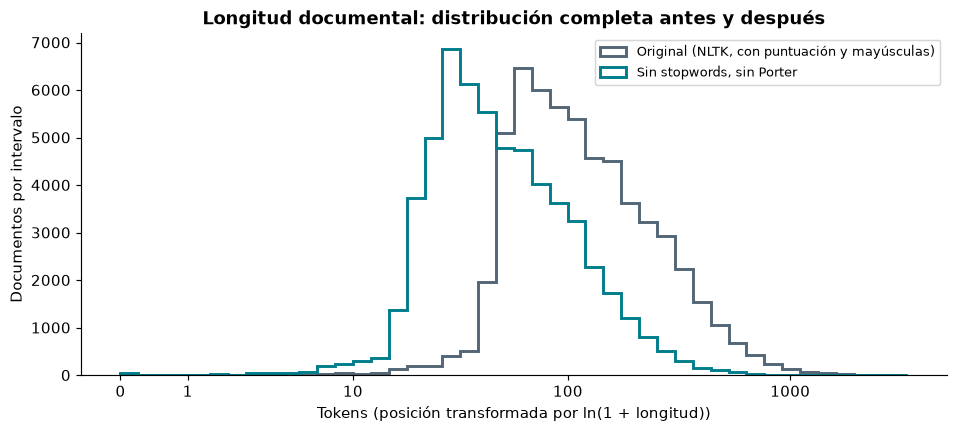

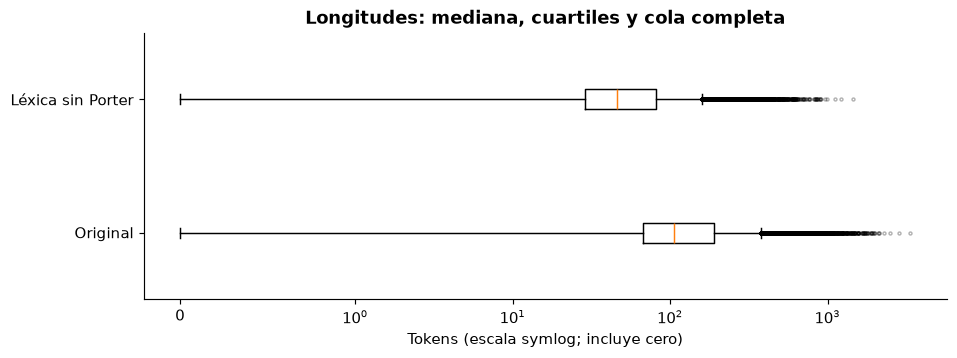

In [4]:
def length_table(section):
    rows = {}
    for stage in STAGES:
        stats = summary[section][stage]["length"]
        rows[LABELS[stage]] = {
            key: stats[key]
            for key in (
                "total",
                "mean",
                "median",
                "std_population",
                "min",
                "max",
                "zeros",
            )
        }
        rows[LABELS[stage]].update(
            {f"p{p}": value for p, value in stats["percentiles"].items()}
        )
    return pd.DataFrame.from_dict(rows, orient="index")


display(length_table("documents").round(3))
display(pd.DataFrame(summary["documents"]["lexical"]["shortest"]))
display(pd.DataFrame(summary["documents"]["lexical"]["longest"]))


def values_from_distribution(section, stage):
    dist = summary[section][stage]["length"]["distribution"]
    return np.repeat([int(n) for n in dist], list(dist.values()))


fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
max_length = summary["documents"]["original"]["length"]["max"]
bins = np.linspace(0, np.log1p(max_length), 45)
for stage in ("original", "lexical"):
    ax.hist(
        np.log1p(values_from_distribution("documents", stage)),
        bins=bins,
        histtype="step",
        linewidth=2,
        label=LABELS[stage],
        color=COLORS[stage],
    )
ticks = [0, 1, 10, 100, 1000, 10000]
ticks = [t for t in ticks if t <= max_length]
ax.set_xticks(np.log1p(ticks), labels=ticks)
ax.set(
    title="Longitud documental: distribución completa antes y después",
    xlabel="Tokens (posición transformada por ln(1 + longitud))",
    ylabel="Documentos por intervalo",
)
ax.legend(fontsize=9)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.3), layout="constrained")
ax.boxplot(
    [values_from_distribution("documents", s) for s in ("original", "lexical")],
    orientation="horizontal",
    tick_labels=["Original", "Léxica sin Porter"],
    flierprops={"markersize": 2, "alpha": 0.3},
)
ax.set_xscale("symlog", linthresh=1)
ax.set(
    title="Longitudes: mediana, cuartiles y cola completa",
    xlabel="Tokens (escala symlog; incluye cero)",
)
plt.show()

In [5]:
d = summary["documents"]["lexical"]
display(
    Markdown(
        f"**Observado.** Tras el pipeline sin Porter, media **{d['length']['mean']:.2f}**, "
        f"mediana **{d['length']['median']:.1f}**, p99 **{d['length']['percentiles']['99']:.2f}** "
        f"y máximo **{d['length']['max']}** tokens. Quedan **{d['length']['zeros']}** documentos "
        f"sin tokens y **{d['length_le5']}** con ≤5 tokens (incluidos los vacíos). "
        "Los puntos del boxplot fuera de 1.5 IQR se conservan: no se etiquetan como errores. "
        "**Interpretación.** La diferencia media–mediana y la cola muestran heterogeneidad "
        "que justifica documentar la longitud usada por BM25 y la norma de pesos en TF-IDF. "
        "La distribución por sí sola no determina cuál recupera mejor."
    )
)

**Observado.** Tras el pipeline sin Porter, media **66.61**, mediana **46.0**, p99 **319.00** y máximo **1448** tokens. Quedan **40** documentos sin tokens y **226** con ≤5 tokens (incluidos los vacíos). Los puntos del boxplot fuera de 1.5 IQR se conservan: no se etiquetan como errores. **Interpretación.** La diferencia media–mediana y la cola muestran heterogeneidad que justifica documentar la longitud usada por BM25 y la norma de pesos en TF-IDF. La distribución por sí sola no determina cuál recupera mejor.

## 5. Preprocesamiento y vocabulario

CF suma apariciones en la colección; DF cuenta documentos. El Counter por documento
es una representación Bag of Words que pierde el orden, sin crear una matriz densa.
Se reportan CF y DF juntos para los términos frecuentes. Los **hapax CF=1** aparecen
una sola vez en todo el corpus; **DF=1** también incluye términos repetidos muchas
veces en un único documento. No son cantidades intercambiables.

,vocabulary_size,collection_frequency_total,hapax_cf1,hapax_cf1_pct_types,rare_cf_le5,rare_cf_le5_pct_types,single_document_df1,single_document_df1_pct_types
"Original (NLTK, con puntuación y mayúsculas)",129404.0,9055839.0,71580.0,55.315,102601.0,79.287,76782.0,59.335
Minúsculas + alfanuméricos (diagnóstico),66945.0,7567255.0,27923.0,41.710,46105.0,68.870,30756.0,45.942
"Sin stopwords, sin Porter",66796.0,3838998.0,27923.0,41.803,46104.0,69.022,30756.0,46.045
"Sin stopwords, con Porter",46821.0,3838998.0,20922.0,44.685,33293.0,71.107,23416.0,50.012


tokens_original_to_lexical_pct        57.607
tokens_stopwords_only_pct             49.268
vocabulary_original_to_lexical_pct    48.382
vocabulary_stopwords_only_pct          0.223
vocabulary_porter_pct                 29.904
Name: Reducción (%), dtype: float64

,term,cf,df
0,would,30789,17595
1,money,30149,14795
2,get,21284,14382
3,one,19323,13551
4,people,19031,12067
5,like,18572,13660
6,pay,17155,10088
7,tax,16088,6219
8,make,15920,11607
9,time,15357,10754


,term,cf,df
0,would,30789,17595
1,money,30149,14795
2,get,21284,14382
3,like,18572,13660
4,one,19323,13551
5,people,19031,12067
6,make,15920,11607
7,also,14364,11111
8,time,15357,10754
9,pay,17155,10088


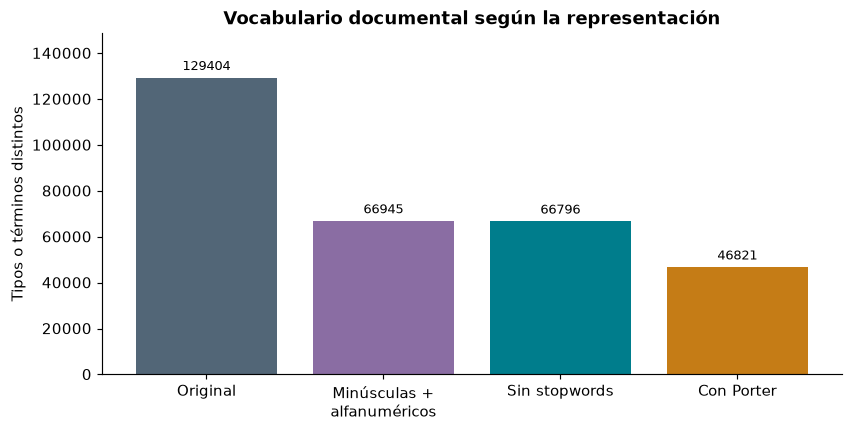

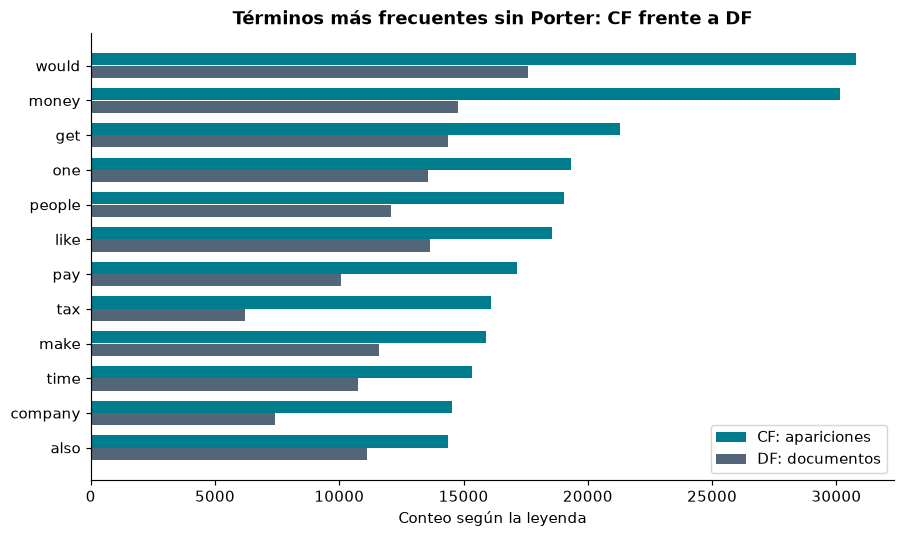

In [6]:
vocab_rows = {}
for stage in STAGES:
    stats = summary["documents"][stage]
    vocab_rows[LABELS[stage]] = {
        k: stats[k]
        for k in (
            "vocabulary_size",
            "collection_frequency_total",
            "hapax_cf1",
            "hapax_cf1_pct_types",
            "rare_cf_le5",
            "rare_cf_le5_pct_types",
            "single_document_df1",
            "single_document_df1_pct_types",
        )
    }
display(pd.DataFrame(vocab_rows).T.round(3))
display(pd.Series(summary["reductions_documents"], name="Reducción (%)").round(3))
display(pd.DataFrame(summary["documents"]["lexical"]["top_by_cf"]))
display(pd.DataFrame(summary["documents"]["lexical"]["top_by_df"][:10]))

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
values = [summary["documents"][s]["vocabulary_size"] for s in STAGES]
bars = ax.bar(
    ["Original", "Minúsculas +\nalfanuméricos", "Sin stopwords", "Con Porter"],
    values,
    color=[COLORS[s] for s in STAGES],
)
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
ax.set_ylim(0, max(values) * 1.15)
ax.set(
    title="Vocabulario documental según la representación",
    ylabel="Tipos o términos distintos",
)
plt.show()

top = pd.DataFrame(summary["documents"]["lexical"]["top_by_cf"][:12]).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5), layout="constrained")
y = np.arange(len(top))
ax.barh(y + 0.18, top.cf, height=0.35, color=COLORS["lexical"], label="CF: apariciones")
ax.barh(y - 0.18, top.df, height=0.35, color=COLORS["original"], label="DF: documentos")
ax.set_yticks(y, top.term)
ax.set(
    title="Términos más frecuentes sin Porter: CF frente a DF",
    xlabel="Conteo según la leyenda",
)
ax.legend(loc="lower right")
plt.show()

In [7]:
red = summary["reductions_documents"]
display(
    Markdown(
        f"**Observado.** Original → léxica elimina **{red['tokens_original_to_lexical_pct']:.2f}%** "
        f"de apariciones. Comparando únicamente la etapa normalizada con la léxica, las "
        f"stopwords explican **{red['tokens_stopwords_only_pct']:.2f}%** de tokens y "
        f"**{red['vocabulary_stopwords_only_pct']:.2f}%** de tipos de esa base. Porter reduce "
        f"el vocabulario léxico **{red['vocabulary_porter_pct']:.2f}%**, manteniendo las longitudes. "
        "**Interpretación.** Filtrar formas frecuentes puede afectar mucho más al número de "
        "apariciones que a la diversidad de tipos. Porter agrupa formas y puede perder "
        "distinciones útiles; sus raíces no tienen por qué ser palabras. "
        "**Hipótesis pendiente.** Esos cambios podrían alterar coincidencias y rankings; "
        "solo una evaluación posterior con qrels puede establecer su efecto en efectividad."
    )
)

**Observado.** Original → léxica elimina **57.61%** de apariciones. Comparando únicamente la etapa normalizada con la léxica, las stopwords explican **49.27%** de tokens y **0.22%** de tipos de esa base. Porter reduce el vocabulario léxico **29.90%**, manteniendo las longitudes. **Interpretación.** Filtrar formas frecuentes puede afectar mucho más al número de apariciones que a la diversidad de tipos. Porter agrupa formas y puede perder distinciones útiles; sus raíces no tienen por qué ser palabras. **Hipótesis pendiente.** Esos cambios podrían alterar coincidencias y rankings; solo una evaluación posterior con qrels puede establecer su efecto en efectividad.

## 6. Consultas test

Se aplica exactamente el pipeline clásico usado para documentos. Las frecuencias
documentales del índice futuro deberán calcularse sobre el corpus, no sobre esta
colección de consultas. OOV significa formas de la consulta ausentes del vocabulario
documental de la misma etapa; se cuentan tipos y apariciones separadamente.

En el JSON, `df` en los agregados de consultas cuenta consultas distintas que contienen la forma. Es una frecuencia descriptiva de consultas, distinta de la DF del corpus que se usará para IDF.

,total,mean,median,std_population,min,max,zeros,p1,p5,p25,p50,p75,p90,p95,p99
"Original (NLTK, con puntuación y mayúsculas)",7994,12.336,12.0,4.895,2,33,0,3.0,5.0,9.00,12.0,16.0,19.0,21.0,26.00
Minúsculas + alfanuméricos (diagnóstico),6939,10.708,10.0,4.295,1,31,0,3.0,4.0,7.75,10.0,14.0,16.0,18.0,21.53
"Sin stopwords, sin Porter",3920,6.049,6.0,2.306,1,15,0,2.0,3.0,4.00,6.0,7.0,9.0,10.0,12.00
"Sin stopwords, con Porter",3920,6.049,6.0,2.306,1,15,0,2.0,3.0,4.00,6.0,7.0,9.0,10.0,12.00


,vocabulary_size,collection_frequency_total,oov_types,oov_tokens,oov_tokens_pct
"Original (NLTK, con puntuación y mayúsculas)",2037.0,7994.0,57.0,58.0,0.726
Minúsculas + alfanuméricos (diagnóstico),1674.0,6939.0,9.0,9.0,0.130
"Sin stopwords, sin Porter",1566.0,3920.0,9.0,9.0,0.230
"Sin stopwords, con Porter",1235.0,3920.0,9.0,9.0,0.230


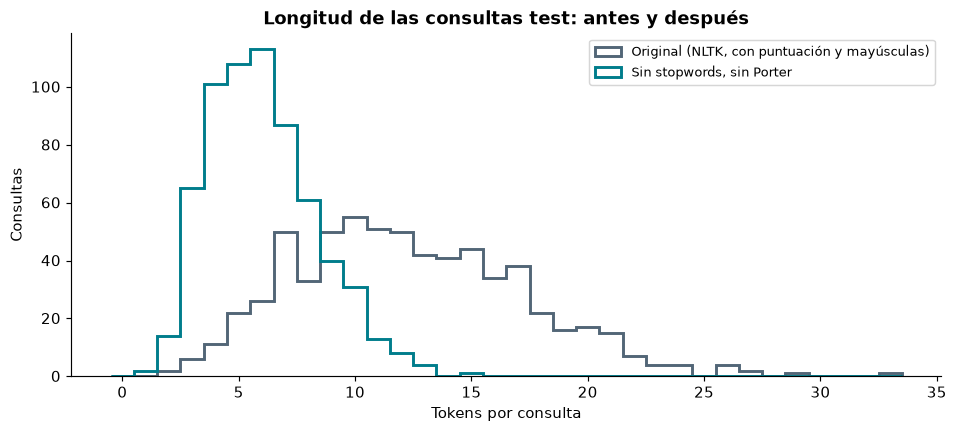

**Observado.** Hay 648 consultas test frente a 6648 globales. La media léxica es 6.05 tokens y quedan 0 consultas vacías tras el pipeline. Los tokens OOV representan 0.230% de las apariciones léxicas test. **Interpretación.** La longitud y la cobertura léxica caracterizan la evidencia disponible; compartir vocabulario no asegura relevancia.

In [8]:
display(length_table("queries_test").round(3))
display(
    pd.DataFrame(
        {
            LABELS[s]: {
                k: summary["queries_test"][s][k]
                for k in (
                    "vocabulary_size",
                    "collection_frequency_total",
                    "oov_types",
                    "oov_tokens",
                    "oov_tokens_pct",
                )
            }
            for s in STAGES
        }
    ).T.round(3)
)
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
maximum = summary["queries_test"]["original"]["length"]["max"]
bins = np.arange(-0.5, maximum + 1.5, 1)
for stage in ("original", "lexical"):
    ax.hist(
        values_from_distribution("queries_test", stage),
        bins=bins,
        histtype="step",
        linewidth=2,
        color=COLORS[stage],
        label=LABELS[stage],
    )
ax.set(
    title="Longitud de las consultas test: antes y después",
    xlabel="Tokens por consulta",
    ylabel="Consultas",
)
ax.legend(fontsize=9)
plt.show()
display(
    Markdown(
        f"**Observado.** Hay {summary['counts']['test_queries']} consultas test frente a "
        f"{summary['counts']['global_queries']} globales. La media léxica es "
        f"{summary['queries_test']['lexical']['length']['mean']:.2f} tokens y quedan "
        f"{summary['queries_test']['lexical']['length']['zeros']} consultas vacías tras el pipeline. "
        f"Los tokens OOV representan {summary['queries_test']['lexical']['oov_tokens_pct']:.3f}% "
        "de las apariciones léxicas test. **Interpretación.** La longitud y la cobertura "
        "léxica caracterizan la evidencia disponible; compartir vocabulario no asegura relevancia."
    )
)

## 7. Relevancia test e implicaciones para la evaluación

Se cuentan relevantes **juzgados** por consulta (score > 0). Los documentos sin qrel
no están demostrados irrelevantes; la evaluación del proyecto solo puede usar los
juicios disponibles. Se muestran todos los valores de la distribución, sin truncar la cola.

count                                 648.000000
judgment_pairs                       1706.000000
unique_relevant_documents            1706.000000
total                                1706.000000
min                                     1.000000
max                                    15.000000
mean                                    2.632716
median                                  2.000000
std_population                          2.061024
queries_le2                           404.000000
queries_gt10                            6.000000
relevant_documents_empty_original       1.000000
relevant_documents_empty_lexical        1.000000
Name: Relevancia test, dtype: float64

1      1.0
5      1.0
25     1.0
50     2.0
75     3.0
90     5.0
95     7.0
99    10.0
Name: Percentiles de relevantes por consulta, dtype: float64

,doc_id,qids
0,117276,[5206]


,Consultas
Relevantes juzgados,
1,220
2,184
3,103
4,56
5,29
6,20
7,13
8,8
9,3


,qid,consulta,relevantes
0,10039,Do individual investors use Google to obtain stock quotes?,1
1,10137,F-1 student investing in foreign markets,1
2,10152,What does a high operating margin but a small but positive ROE imply about a company?,1
3,10482,Rollover into bond fund to do dollar cost averaging [duplicate],1
4,10547,How much do brokerages pay exchanges per trade?,1
5,2348,Why can't you just have someone invest for you and split the profits (and losses) with him?,15
6,5993,Why would anyone want to pay off their debts in a way other than “highest interest” first?,15
7,6005,Why might it be advisable to keep student debt vs. paying it off quickly?,13
8,6131,Is it ever a good idea to close credit cards?,12
9,776,"Can saving/investing 15% of your income starting age 25, likely make you a millionaire?",12


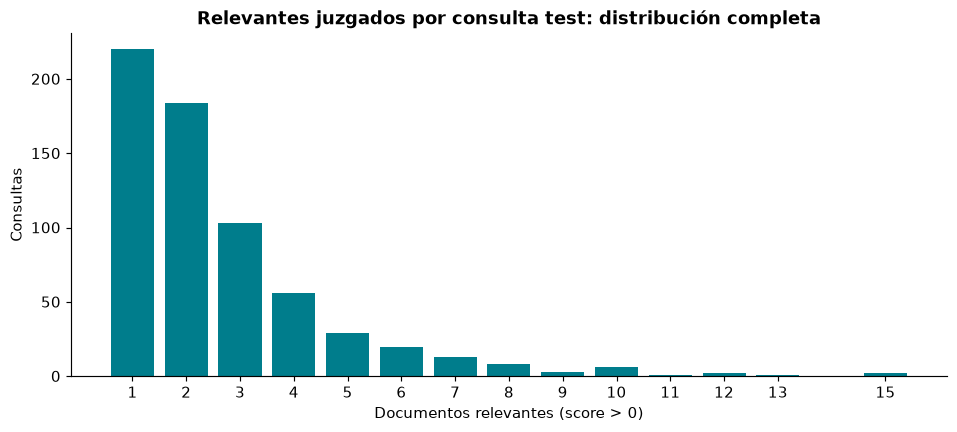

**Observado.** 404 de 648 consultas (62.35%) tienen ≤2 relevantes; 6 tienen más de 10. **Interpretación.** Para R relevantes, P@10 divide por 10 y no puede superar min(R,10)/10 según estos qrels. El promedio de esos techos es **0.2605**. R@10 divide por R: su techo es min(R,10)/R; con R=1 cada acierto cambia el recall en una unidad. El techo macro de R@10 es **0.9980**. AP@1000 divide por todos los relevantes, incluidos los que queden fuera del corte. MAP@1000 promedia las consultas de qrels con el mismo peso, aunque R difiera; su techo ideal es **1.0000**. Estos son límites matemáticos de rankings ideales, **no métricas obtenidas por modelos**. Una consulta sin ranking aportará 0 según el contrato del proyecto. Se observa **1 documento relevante vacío**: sus IDs se muestran arriba para revisar el caso en la evaluación posterior. Su juicio se conserva, aunque no proporcione evidencia textual.

In [9]:
r = summary["relevance_test"]
display(
    pd.Series(
        {
            k: r[k]
            for k in (
                "count",
                "judgment_pairs",
                "unique_relevant_documents",
                "total",
                "min",
                "max",
                "mean",
                "median",
                "std_population",
                "queries_le2",
                "queries_gt10",
                "relevant_documents_empty_original",
                "relevant_documents_empty_lexical",
            )
        },
        name="Relevancia test",
    )
)
display(pd.Series(r["percentiles"], name="Percentiles de relevantes por consulta"))
display(pd.DataFrame(r["empty_relevant_examples"]))
dist = pd.Series(
    {int(n): count for n, count in r["distribution"].items()}, name="Consultas"
)
display(dist.to_frame().rename_axis("Relevantes juzgados"))
examples = [
    {"qid": q, "consulta": queries[q], "relevantes": r["example_counts"][q]}
    for q in [*r["fewest"], *r["most"]]
]
with pd.option_context("display.max_colwidth", 100):
    display(pd.DataFrame(examples).drop_duplicates("qid"))
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.bar(dist.index, dist.values, color=COLORS["lexical"], width=0.8)
ax.set_xticks(sorted(dist.index))
ax.set(
    title="Relevantes juzgados por consulta test: distribución completa",
    xlabel="Documentos relevantes (score > 0)",
    ylabel="Consultas",
)
plt.show()
display(
    Markdown(
        f"**Observado.** {r['queries_le2']} de {r['count']} consultas "
        f"({100 * r['queries_le2'] / r['count']:.2f}%) tienen ≤2 relevantes; "
        f"{r['queries_gt10']} tienen más de 10. **Interpretación.** Para R relevantes, "
        "P@10 divide por 10 y no puede superar min(R,10)/10 según estos qrels. "
        f"El promedio de esos techos es **{r['macro_oracle_ceiling_p10']:.4f}**. "
        "R@10 divide por R: su techo es min(R,10)/R; con R=1 cada acierto cambia "
        f"el recall en una unidad. El techo macro de R@10 es **{r['macro_oracle_ceiling_r10']:.4f}**. "
        "AP@1000 divide por todos los relevantes, incluidos los que queden fuera del corte. "
        "MAP@1000 promedia las consultas de qrels con el mismo peso, aunque R difiera; "
        f"su techo ideal es **{r['macro_oracle_ceiling_ap1000']:.4f}**. "
        "Estos son límites matemáticos de rankings ideales, **no métricas obtenidas por modelos**. "
        "Una consulta sin ranking aportará 0 según el contrato del proyecto. "
        f"Se observa **{r['relevant_documents_empty_original']} documento relevante vacío**: "
        "sus IDs se muestran arriba para revisar el caso en la evaluación posterior. "
        "Su juicio se conserva, aunque no proporcione evidencia textual."
    )
)

## 8. Validación de resultados y exportación

Además de las pruebas manuales pequeñas de `tests/test_eda.py`, se contrastan las
sumas de las distribuciones, los totales de tokens, el efecto de Porter y los conteos
reales. Se recalcula independientemente CF y DF para tres términos frecuentes de un
subconjunto fijo de documentos. Esta comprobación valida el agregado, sin evaluar modelos.

In [10]:
for section, size in (("documents", len(corpus)), ("queries_test", len(queries))):
    for stage in STAGES:
        stats = summary[section][stage]
        distribution = stats["length"]["distribution"]
        assert sum(distribution.values()) == size
        assert (
            sum(int(n) * count for n, count in distribution.items())
            == stats["collection_frequency_total"]
        )
        assert sum(stats["cf_distribution"].values()) == stats["vocabulary_size"]
        assert (
            sum(int(cf) * types for cf, types in stats["cf_distribution"].items())
            == stats["collection_frequency_total"]
        )
    assert summary[section]["lexical"]["length"] == summary[section]["porter"]["length"]
assert (
    sum(int(n) * count for n, count in r["distribution"].items()) == r["total"] == 1706
)
assert sum(r["distribution"].values()) == len(queries)
assert r["score_distribution"] == {"1": 1706}
dataset_reference = (ROOT / "docs" / "DATASET.md").read_text(encoding="utf-8")
for source in summary["provenance"]["sources"]:
    assert source["sha256"] in dataset_reference, (
        "Archivo distinto del verificado en #2"
    )

sample_ids = sorted(corpus)[:100]
sample_tokens = [
    preprocess(f"{corpus[i].title} {corpus[i].text}".strip()) for i in sample_ids
]
from ris.eda import profile_texts

_, sample_profiles = profile_texts(
    (i, f"{corpus[i].title} {corpus[i].text}".strip()) for i in sample_ids
)
for term in [entry["term"] for entry in d["top_by_cf"][:3]]:
    assert sample_profiles["lexical"].cf[term] == sum(
        tokens.count(term) for tokens in sample_tokens
    )
    assert sample_profiles["lexical"].df[term] == sum(
        term in tokens for tokens in sample_tokens
    )
del sample_tokens, sample_profiles
write_summary(summary, ROOT / "reports" / "eda_summary.json")
assert (
    json.loads((ROOT / "reports" / "eda_summary.json").read_text(encoding="utf-8"))
    == summary
)
excerpt = report_excerpt(summary)
(ROOT / "docs" / "informe").mkdir(parents=True, exist_ok=True)
(ROOT / "docs" / "informe" / "04_descripcion_corpus.md").write_text(
    excerpt, encoding="utf-8"
)
print("Validaciones reales y consistencia JSON/notebook: correctas")
print("Exportados: reports/eda_summary.json; docs/informe/04_descripcion_corpus.md")

Validaciones reales y consistencia JSON/notebook: correctas
Exportados: reports/eda_summary.json; docs/informe/04_descripcion_corpus.md


## 9. Discusión, limitaciones y conclusiones

**Resultados observados:** las tablas y gráficos describen FiQA completo y test en
las revisiones fijadas; el resumen siguiente se genera de los mismos agregados.
Las distribuciones completas están en JSON; las salidas del notebook se limitan a
tablas pequeñas, ejemplos identificables y gráficos, sin copias del corpus.

**Interpretaciones:** la longitud, el vocabulario y el número de relevantes son
dimensiones distintas. La reducción de tokens afecta a las longitudes; Porter
agrupa tipos sin eliminar apariciones. Bag of Words conserva conteos pero pierde
orden y contexto. TF-IDF normaliza con la norma del vector; BM25 usa la longitud
relativa a la media. Ni el tamaño del vocabulario ni el solapamiento léxico establecen
por sí solos la utilidad de un resultado para una necesidad.

**Hipótesis y límites:** las consecuencias de stopwords y Porter para los rankings
requieren #11 y #12. No se seleccionan parámetros con test. No se infieren resultados
de los cuatro modelos ni se calcula la tokenización del encoder MiniLM; el modelo
denso recibirá texto original. Los resultados solo caracterizan FiQA y los qrels
disponibles, sin garantizar cobertura exhaustiva ni generalización a otros dominios.
No se corrigen textos, HTML, duplicados semánticos o contenido financiero durante
este EDA: cambiar el corpus o el pipeline excedería #4.

**Relación con clase:** *Modelo vectorial* ilustra TF cruda e IDF base 10; el proyecto
fija `1+ln(tf)`, `ln(N/df)` y L2, sin suavizado. Cambiar solo la base de IDF escala
uniformemente los pesos y conserva el coseno; cambiar TF sí puede alterar rankings.
El ejercicio de *BM25* usa `k1=1.2`; se mantiene `k1=1.5, b=0.75` del plan y su IDF
positiva. Las decisiones del proyecto prevalecen sobre ejemplos didácticos.

In [11]:
display(
    Markdown(
        excerpt.replace(
            "# Descripción del corpus utilizado", "### Resumen reutilizable para #17", 1
        )
    )
)
display(pd.Series(summary["provenance"]["versions"], name="Versiones utilizadas"))
display(
    pd.DataFrame(summary["provenance"]["sources"])[
        ["repo", "revision", "file", "sha256"]
    ]
)

### Resumen reutilizable para #17

FiQA, en su versión BEIR en inglés y de dominio financiero, contiene 57 638 documentos y 6 648 consultas globales. El split test comprende 648 consultas distintas y 1 706 pares juzgados, todos con score 1. Los 57 638 títulos están vacíos; se conservan los 38 textos vacíos.

Tras el pipeline inglés acordado (NLTK, minúsculas, tokens alfanuméricos y stopwords), los documentos tienen media 66.61, mediana 46.0 y percentil 99 319.00 tokens. Las consultas test tienen media 6.05 tokens. El vocabulario documental contiene 66 796 términos; Porter lo reduce a 46 821 (29.90% respecto de la versión sin Porter), sin alterar la cantidad de apariciones. Esta reducción no demuestra una mejora de recuperación.

Hay 1 706 documentos relevantes test distintos. Por consulta se observan entre 1 y 15 relevantes (media 2.633, mediana 2.0); 404 consultas tienen como máximo dos. El techo macro teórico de P@10 según estos qrels es 0.2605; no es el resultado de un recuperador. Los juicios disponibles no establecen la irrelevancia de todos los documentos sin juzgar. Hay 1 documento relevante sin texto, un caso que debe inspeccionarse al evaluar la evidencia textual disponible. La efectividad se medirá posteriormente mediante P@10, R@10 y MAP@1000, sin ajustar hiperparámetros con test.

Fuentes: [corpus y consultas](https://huggingface.co/datasets/BeIR/fiqa), [qrels](https://huggingface.co/datasets/BeIR/fiqa-qrels), [revisiones y hashes](../DATASET.md), [notebook ejecutado](../../notebooks/04_eda_fiqa.ipynb) y [agregados reproducibles](../../reports/eda_summary.json). Fundamento conceptual: Iván Carrera, *Fundamentos de Recuperación de Información* (pp. 20–33), *Modelo vectorial* (pp. 5–15, 24) y *Modelo BM25* (pp. 4–8, 14), material docente EPN.


numpy               2.5.4
nltk               3.10.4
pandas              3.1.1
matplotlib         3.11.2
huggingface_hub     2.4.0
pyarrow            26.0.1
Name: Versiones utilizadas, dtype: str

,repo,revision,file,sha256
0,BeIR/fiqa,979c07a7cb5ccc6ca009792241fa1250b98055dd,corpus/corpus-00000-of-00001.parquet,b36bb07dab3bfad488190818828e749a52faf5ba391c1d...
1,BeIR/fiqa,979c07a7cb5ccc6ca009792241fa1250b98055dd,queries/queries-00000-of-00001.parquet,e9b3863724ffd538d8efff19684ef8ae495bdbddd96b35...
2,BeIR/fiqa-qrels,252958f2d646e22cab6d0c72dd3f0d5de6d0655a,train.tsv,e46a99529aa61b12e086a5c057e4e0ecaeda9502e53d5f...
3,BeIR/fiqa-qrels,252958f2d646e22cab6d0c72dd3f0d5de6d0655a,dev.tsv,03b27e547cd29dc721c3b93ce8ddd70df6b2d0ce954d8e...
4,BeIR/fiqa-qrels,252958f2d646e22cab6d0c72dd3f0d5de6d0655a,test.tsv,6adc2a640dcdd22bb8b3858f89107adef2a7c3db20a635...


## 10. Referencias

- BeIR, [FiQA: corpus y consultas](https://huggingface.co/datasets/BeIR/fiqa) y
  [FiQA-qrels](https://huggingface.co/datasets/BeIR/fiqa-qrels). Revisiones, hashes y
  política de carga: [docs/DATASET.md](../docs/DATASET.md) y `summary["provenance"]`.
- Carrera, Iván. *Fundamentos de Recuperación de Información*, EPN, pp. 4–9,
  17–33 y 36: documentos, consultas, relevancia, tokens, tipos y políticas léxicas.
- Carrera, Iván. *Modelo vectorial, TF-IDF y ranking clásico*, EPN, pp. 5–15,
  17–20 y 24: Bag of Words, TF, DF, IDF, norma y alcance.
- Carrera, Iván. *Modelo BM25*, EPN, 28 de octubre de 2026, pp. 4–8 y 14:
  saturación, longitud y variantes de ponderación.
- Carrera, Iván. *Revisión de Machine Learning*, EPN, pp. 5–6: representación,
  generalización e hiperparámetros (contexto conceptual).

El material docente se consulta localmente y se parafrasea; no se distribuyen los PDF.
La especificación oficial, los criterios de #4, los contratos y el código aprobado
determinan la metodología efectiva.